# Session 4 exercise, three one-sample tests

> **A client's ledger reports an average daily transaction value of 520.**
> **You sample 40 actual trading days. Is 520 supported by the evidence, or overstated?**

A one-sample test compares one group against a single claimed value. You will run it three times, back to back, on three industries: **audit** (this page), then **manufacturing** and **sales** further down. Same five-step recipe each time: state the hypotheses, run the test, read the p-value against alpha, confirm with a confidence interval, and ask which error would have cost more. Work through all three, then push Claude on the closing reflection.

## Scenario 1: audit
### Step 0, the sample

Load the 40 sampled days. These are the actual recorded daily averages the audit pulled.

n           = 40
sample mean = 482.01
sample SD   = 78.39
claimed     = 520.00


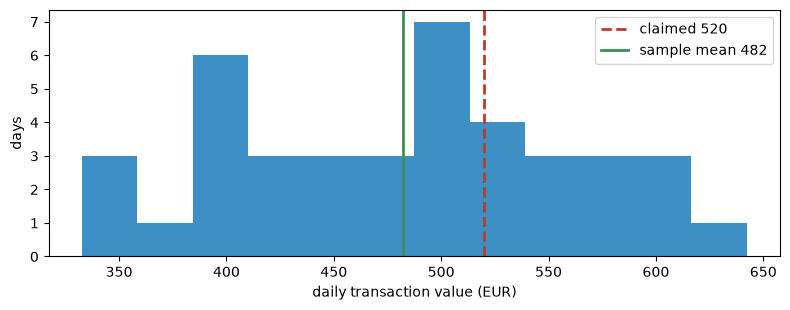

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(21)
sample = np.round(rng.normal(472, 78, 40), 2)   # the 40 sampled days (EUR)
claimed = 520.0                                 # the client's reported average
alpha = 0.05

print(f'n           = {sample.size}')
print(f'sample mean = {sample.mean():,.2f}')
print(f'sample SD   = {sample.std(ddof=1):,.2f}')
print(f'claimed     = {claimed:,.2f}')

plt.figure(figsize=(8, 3.2))
plt.hist(sample, bins=12, color='#0D73B8', alpha=0.8)
plt.axvline(claimed, color='#C0392B', lw=2, ls='--', label=f'claimed {claimed:,.0f}')
plt.axvline(sample.mean(), color='#3E8E5A', lw=2, label=f'sample mean {sample.mean():,.0f}')
plt.xlabel('daily transaction value (EUR)'); plt.ylabel('days'); plt.legend()
plt.tight_layout(); plt.show()

## Step 1, state the hypotheses

Before touching the data, write them down. The null is the status quo claim with an equality; the alternative is what you would need evidence to conclude.

- **H0:** the true average daily transaction value equals 520.  `mu = 520`
- **Ha:** it differs from 520.  `mu =/= 520`  (two-sided)

We will reject H0 only if the sample would be surprising when 520 is true.

## Step 2, run the one-sample t-test

The population SD is unknown, so this is a t-test. `scipy.stats.ttest_1samp` does it in one line and returns the test statistic and the two-sided p-value.

In [2]:
t_stat, p_value = stats.ttest_1samp(sample, popmean=claimed)
print(f't statistic = {t_stat:.3f}')
print(f'p-value     = {p_value:.4f}')

t statistic = -3.065
p-value     = 0.0039


## Step 3, the verdict

Compare the p-value with alpha. If `p < alpha`, the data is too surprising for the claim to stand, so reject H0.

In [3]:
if p_value < alpha:
    print(f'p = {p_value:.4f} < {alpha}: reject H0.')
    direction = 'below' if sample.mean() < claimed else 'above'
    print(f'The sample mean ({sample.mean():,.2f}) sits {direction} the claimed 520.')
    print('The reported average is not supported by the sample: flag it for review.')
else:
    print(f'p = {p_value:.4f} >= {alpha}: fail to reject H0.')
    print('No evidence the true average differs from the claimed 520.')

p = 0.0039 < 0.05: reject H0.
The sample mean (482.01) sits below the claimed 520.
The reported average is not supported by the sample: flag it for review.


## Step 4, confirm with a confidence interval

A 95% confidence interval should tell the same story: the claimed value falls outside the interval exactly when the two-sided test rejects it at the same level.

In [4]:
mean, sd, n = sample.mean(), sample.std(ddof=1), sample.size
se = sd / np.sqrt(n)
tstar = stats.t.ppf(0.975, df=n - 1)
lo, hi = mean - tstar * se, mean + tstar * se
inside = lo <= claimed <= hi
print(f'95% CI for the true average: {lo:,.2f} to {hi:,.2f}')
print(f'claimed 520 is {"inside" if inside else "OUTSIDE"} the interval')
print('The interval and the test agree.')

95% CI for the true average: 456.94 to 507.08
claimed 520 is OUTSIDE the interval
The interval and the test agree.


## Scenario 2: manufacturing
### Step 0, the sample

A packet-filling line is labelled 500g. Food-labelling rules care specifically about *under*-filling, not over-filling, so this will be a one-sided test. Load 30 sampled packets, weighed off the line.

n           = 30
sample mean = 496.38 g
sample SD   = 8.10 g
label claim = 500.0 g


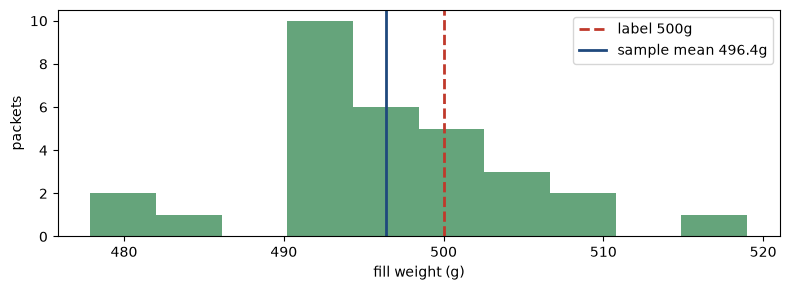

In [5]:
fill_rng = np.random.default_rng(23)
fill_sample = np.round(fill_rng.normal(496.5, 8.0, 30), 1)   # 30 sampled packets (g)
fill_label = 500.0                                           # the label claim

print(f'n           = {fill_sample.size}')
print(f'sample mean = {fill_sample.mean():,.2f} g')
print(f'sample SD   = {fill_sample.std(ddof=1):,.2f} g')
print(f'label claim = {fill_label:,.1f} g')

plt.figure(figsize=(8, 3.0))
plt.hist(fill_sample, bins=10, color='#3E8E5A', alpha=0.8)
plt.axvline(fill_label, color='#C0392B', lw=2, ls='--', label=f'label {fill_label:,.0f}g')
plt.axvline(fill_sample.mean(), color='#1F497D', lw=2, label=f'sample mean {fill_sample.mean():,.1f}g')
plt.xlabel('fill weight (g)'); plt.ylabel('packets'); plt.legend()
plt.tight_layout(); plt.show()

### Step 1, state the hypotheses

- **H0:** the true mean fill weight equals 500g.  `mu = 500`
- **Ha:** it is *less than* 500g (one-sided: regulators only act on under-filling).  `mu < 500`

alpha = 0.05, same as every scenario in this notebook.

In [6]:
fill_t, fill_p = stats.ttest_1samp(fill_sample, popmean=fill_label, alternative='less')
print(f't statistic = {fill_t:.3f}')
print(f'p-value     = {fill_p:.4f}')

if fill_p < alpha:
    print(f'p = {fill_p:.4f} < {alpha}: reject H0.')
    print('The line is running light: evidence of under-filling, worth a line check.')
else:
    print(f'p = {fill_p:.4f} >= {alpha}: fail to reject H0.')
    print('No evidence the line is under-filling.')

t statistic = -2.446
p-value     = 0.0104
p = 0.0104 < 0.05: reject H0.
The line is running light: evidence of under-filling, worth a line check.


### Step 2, confirm with a confidence interval

A one-sided test pairs naturally with a one-sided bound, but a standard two-sided 95% CI tells a consistent story here too: if the label claim sits below the interval, that already says the true mean is higher than 500 is implausible... in this case we expect the opposite, the claim sitting *above* the interval.

In [7]:
fm, fs, fn = fill_sample.mean(), fill_sample.std(ddof=1), fill_sample.size
fse = fs / np.sqrt(fn)
ftstar = stats.t.ppf(0.975, df=fn - 1)
flo, fhi = fm - ftstar * fse, fm + ftstar * fse
print(f'95% CI for the true mean fill weight: {flo:,.2f} to {fhi:,.2f} g')
print(f'label claim 500 is {"inside" if flo <= fill_label <= fhi else "OUTSIDE (above the interval)"} the interval')

95% CI for the true mean fill weight: 493.35 to 499.41 g
label claim 500 is OUTSIDE (above the interval) the interval


## Scenario 3: sales
### Step 0, the sample

A store changed its layout two months ago. Historically the store averaged 1,200 in daily sales. Load 25 days of sales recorded since the change.

n           = 25
sample mean = 1,268.00
sample SD   = 102.54
benchmark   = 1,200.0


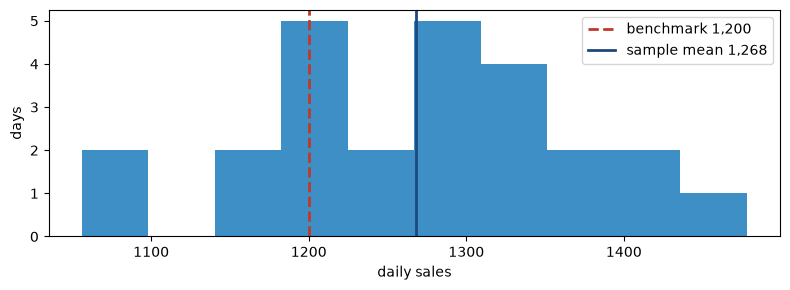

In [8]:
sales_rng = np.random.default_rng(31)
sales_sample = np.round(sales_rng.normal(1265, 120, 25), 0)   # 25 days since the change
sales_benchmark = 1200.0                                       # the historical average

print(f'n           = {sales_sample.size}')
print(f'sample mean = {sales_sample.mean():,.2f}')
print(f'sample SD   = {sales_sample.std(ddof=1):,.2f}')
print(f'benchmark   = {sales_benchmark:,.1f}')

plt.figure(figsize=(8, 3.0))
plt.hist(sales_sample, bins=10, color='#0D73B8', alpha=0.8)
plt.axvline(sales_benchmark, color='#C0392B', lw=2, ls='--', label=f'benchmark {sales_benchmark:,.0f}')
plt.axvline(sales_sample.mean(), color='#1F497D', lw=2, label=f'sample mean {sales_sample.mean():,.0f}')
plt.xlabel('daily sales'); plt.ylabel('days'); plt.legend()
plt.tight_layout(); plt.show()

### Step 1, state the hypotheses

- **H0:** the true mean daily sales still equals the 1,200 benchmark (the change did nothing).  `mu = 1200`
- **Ha:** it is *greater than* 1,200 (one-sided: the store wants to know if the change helped).  `mu > 1200`

In [9]:
sales_t, sales_p = stats.ttest_1samp(sales_sample, popmean=sales_benchmark, alternative='greater')
print(f't statistic = {sales_t:.3f}')
print(f'p-value     = {sales_p:.4f}')

if sales_p < alpha:
    print(f'p = {sales_p:.4f} < {alpha}: reject H0.')
    print('Sales genuinely rose: evidence the layout change helped.')
else:
    print(f'p = {sales_p:.4f} >= {alpha}: fail to reject H0.')
    print('No evidence the change moved sales; the gap could just be noise.')

t statistic = 3.316
p-value     = 0.0014
p = 0.0014 < 0.05: reject H0.
Sales genuinely rose: evidence the layout change helped.


### Step 2, confirm with a confidence interval

In [10]:
sm, ss, sn = sales_sample.mean(), sales_sample.std(ddof=1), sales_sample.size
sse = ss / np.sqrt(sn)
ststar = stats.t.ppf(0.975, df=sn - 1)
slo, shi = sm - ststar * sse, sm + ststar * sse
print(f'95% CI for the true mean daily sales: {slo:,.2f} to {shi:,.2f}')
print(f'benchmark 1,200 is {"inside" if slo <= sales_benchmark <= shi else "OUTSIDE"} the interval')

95% CI for the true mean daily sales: 1,225.67 to 1,310.33
benchmark 1,200 is OUTSIDE the interval


## Debrief: three scenarios, one method

Push Claude on these, pulling in all three scenarios above:
1. **One side or two?** The manufacturing and sales tests were one-sided; the audit test was two-sided. What would change in each p-value if you ran it the other way, and would any verdict flip?
2. **Which error costs more, each time?** For the audit case, for the manufacturing case, and for the sales case: if this test is wrong, is it the Type I or the Type II mistake that does more damage? Are the answers the same across all three?
3. **Halve the margin.** Pick one scenario's confidence interval. Roughly how large a sample would you need to halve its margin of error, holding the SD fixed?
4. **Significant, but how much?** The sales lift and the manufacturing shortfall were both statistically significant here. Which one, if either, is also *practically* significant, and what extra information would you need to decide?
5. **Same engine, three costumes.** All three tests ran through the identical recipe (state H0/Ha, run the t-test, read p against alpha, confirm with a CI). What does that tell you about what a hypothesis test actually is?